# 05 — Repeated-trip variability and OD hotspots (Guo-inspired)
**Paper 3 · Toronto Bike Share · June 2024 · Behavioural baseline, before environmental exposure**

This notebook extends `03_guo_2026_travel_time_baseline.ipynb` and `04_guo_bike_type_speed_sensitivity.ipynb`.

**Research questions**
1. Which directed origin–destination (OD) pairs have consistently large **recorded–modelled time differences**?
2. Where is **recorded rental time** most variable among repeated trips, independently of the GraphHopper estimate?
3. How reliable are apparent hotspots when we account for sample size, skewness, extreme rentals and station-location uncertainty?
4. Which patterns differ by bicycle type?

**Important:** The records contain station-to-station rentals, **not observed trajectories**. A large positive difference does not necessarily mean an inefficient route or *unnecessary environmental exposure*. The modelled route comes from a later OSM snapshot, and some station coordinates are provisional.

In [1]:
from pathlib import Path
import sqlite3, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.collections import LineCollection

ROOT = Path("/scratch/project_2010417/paper3/toronto-bike-exposure")
DATA = ROOT / "data/processed"
OUT = ROOT / "outputs/guo_od_hotspots"
OUT.mkdir(parents=True, exist_ok=True)
TRIPS = DATA / "bikeshare_june_2024_validated.parquet"
ROUTES = DATA / "full_june_routes.sqlite"
assert TRIPS.exists(), TRIPS
assert ROUTES.exists(), ROUTES
print("Writing outputs to:", OUT)

Writing outputs to: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_od_hotspots


## 1 — Build the trip–route analytical table
Reuse the **same basic restrictions as notebook 04** to make the comparisons interpretable: positive duration, different stations, valid time, matched route, recognised bike type, 1–90 min recorded duration, 0.5–90 min modelled time, and at least 100 m modelled distance.

The distinction between these filters and the full population will be reported.

In [2]:
def norm_id(s):
    return s.astype("string").str.strip().str.replace(r"\.0+$", "", regex=True)

t = pd.read_parquet(TRIPS, columns=[
    "Start_Station_Id", "End_Station_Id", "Trip_Duration", "Start_Time", "Bike_Model"
])
n_original = len(t)
t["Start_Station_Id"] = norm_id(t["Start_Station_Id"])
t["End_Station_Id"] = norm_id(t["End_Station_Id"])
t["duration_s"] = pd.to_numeric(t["Trip_Duration"], errors="coerce")
t["started_at"] = pd.to_datetime(t["Start_Time"], errors="coerce")
valid = (
    t.duration_s.gt(0) &
    t.Start_Station_Id.notna() & t.End_Station_Id.notna() &
    t.Start_Station_Id.ne(t.End_Station_Id) & t.started_at.notna()
).fillna(False)
t = t.loc[valid].copy()

with sqlite3.connect(ROUTES) as con:
    r = pd.read_sql_query(
        "SELECT start_id,end_id,distance_m,time_min FROM routes "
        "WHERE geometry_json IS NOT NULL AND error IS NULL", con
    )
r["start_id"] = norm_id(r["start_id"])
r["end_id"] = norm_id(r["end_id"])
assert not r.duplicated(["start_id", "end_id"]).any()
r["distance_m"] = pd.to_numeric(r.distance_m, errors="coerce")
r["time_min"] = pd.to_numeric(r.time_min, errors="coerce")
r = r.loc[r.distance_m.gt(0) & r.time_min.gt(0)]

df = t.merge(
    r, left_on=["Start_Station_Id", "End_Station_Id"],
    right_on=["start_id", "end_id"], how="inner", validate="many_to_one"
)
n_matched = len(df)
bm = df.Bike_Model.astype("string").str.upper().str.strip()
df["bike_type"] = np.select(
    [bm.str.startswith("EFIT", na=False), bm.eq("ICONIC").fillna(False)],
    ["Electric", "Conventional"], default="Unknown"
)
df = df.loc[df.bike_type.isin(["Electric", "Conventional"])].copy()
n_classified = len(df)
df["observed_min"] = df.duration_s / 60
df = df.loc[
    df.observed_min.between(1,90) &
    df.time_min.between(.5,90) & df.distance_m.ge(100)
].copy()
df["delta_min"] = df.observed_min - df.time_min
df["positive_delta_min"] = df.delta_min.clip(lower=0)
df["hour"] = df.started_at.dt.hour
df["weekend"] = df.started_at.dt.dayofweek >= 5

print(f"Original trips: {n_original:,}")
print(f"Joined routes (before classification/quality): {n_matched:,}")
print(f"Known bicycle type: {n_classified:,}")
print(f"Quality-filtered analytical trips: {len(df):,} ({len(df)/n_original:.1%} of original)")
print(df.bike_type.value_counts().to_string())
assert len(df) > 0

Original trips: 766,868
Joined routes (before classification/quality): 737,915
Known bicycle type: 737,915
Quality-filtered analytical trips: 730,853 (95.3% of original)
bike_type
Conventional    603250
Electric        127603


## 2 — Repeated directed OD statistics
We use:
- `median_observed_min`: directly observed rental time, within each directed OD
- `iqr_observed_min`: within-OD interquartile range of recorded rental time
- `median_delta_min`: median recorded time **minus** the constant OD modelled time
- `p90_delta_min`: upper tail of the difference distribution
- `share_negative`: fraction of rentals shorter than the model estimate

**Critical subtlety:** Within an OD, the GraphHopper baseline is constant. Therefore `IQR(observed - model) = IQR(observed)`. Extra-time *variability* is not an independently observed path-exposure measure.

In [3]:
KEYS = ["Start_Station_Id", "End_Station_Id"]

def q25(s): return s.quantile(.25)
def q75(s): return s.quantile(.75)
def q90(s): return s.quantile(.90)

od = (
    df.groupby(KEYS, observed=True)
      .agg(
          n=("observed_min", "size"),
          median_observed_min=("observed_min", "median"),
          mean_observed_min=("observed_min", "mean"),
          q25_observed_min=("observed_min", q25),
          q75_observed_min=("observed_min", q75),
          median_delta_min=("delta_min", "median"),
          p90_delta_min=("delta_min", q90),
          mean_positive_delta_min=("positive_delta_min", "mean"),
          share_negative=("delta_min", lambda x: (x < 0).mean()),
          modelled_min=("time_min", "first"),
          distance_m=("distance_m", "first"),
          n_electric=("bike_type", lambda x: (x == "Electric").sum()),
          n_conventional=("bike_type", lambda x: (x == "Conventional").sum()),
      )
      .reset_index()
)
od["iqr_observed_min"] = od.q75_observed_min - od.q25_observed_min
od["distance_km"] = od.distance_m / 1000
od["electric_share"] = od.n_electric / od.n
od.to_csv(OUT / "all_directed_od_statistics.csv", index=False)
print(f"Unique directed OD pairs: {len(od):,}")
print("ODs with ≥20 repeated trips:", (od.n >= 20).sum())
print("ODs with ≥50 repeated trips:", (od.n >= 50).sum())
display(od[["n","median_observed_min","median_delta_min","iqr_observed_min","share_negative"]].describe().round(2))

Unique directed OD pairs: 161,947
ODs with ≥20 repeated trips: 5269
ODs with ≥50 repeated trips: 481


,n,median_observed_min,median_delta_min,iqr_observed_min,share_negative
count,161947.00,161947.00,161947.00,161947.00,161947.00
mean,4.51,19.01,5.70,2.56,0.13
std,6.71,11.94,7.65,4.97,0.27
min,1.00,1.06,-29.38,0.00,0.00
25%,1.00,10.78,1.59,0.00,0.00
50%,2.00,16.48,3.71,1.02,0.00
75%,5.00,24.13,7.13,3.00,0.09
max,225.00,89.97,82.73,84.20,1.00


## 3 — Reliability thresholds and extreme-time diagnostics
High median differences on a small number of rentals can be unstable. Compare thresholds, then use `n ≥ 20` for exploratory hotspot maps. We also flag:
- suspicious near-zero model distances,
- unusually large median time differences,
- exceptionally large within-OD variability.

These flags are **investigation priorities**, not proof of errors.

In [4]:
thresholds = []
for min_n in [5, 10, 20, 30, 50, 100]:
    z = od.loc[od.n >= min_n]
    thresholds.append({
        "minimum_n": min_n,
        "OD_pairs": len(z),
        "represented_trips": int(z.n.sum()),
        "share_analytical_trips": z.n.sum()/len(df),
        "median_of_OD_median_delta": z.median_delta_min.median(),
        "median_of_OD_IQR": z.iqr_observed_min.median(),
    })
threshold_table = pd.DataFrame(thresholds)
display(threshold_table.round(3))
threshold_table.to_csv(OUT/"threshold_sensitivity.csv", index=False)

MIN_N = 20
eligible = od.loc[od.n >= MIN_N].copy()
eligible["flag_high_delta"] = eligible.median_delta_min > 20
eligible["flag_high_variability"] = eligible.iqr_observed_min > 15
eligible["flag_short_distance"] = eligible.distance_m < 250
print(f"Mapping subset: {len(eligible):,} ODs, {eligible.n.sum():,} trips")
print("Flags:", eligible[["flag_high_delta","flag_high_variability","flag_short_distance"]].sum().to_dict())
print("\nTop 12 median differences (sample size >=20):")
display(eligible.nlargest(12,"median_delta_min")[
    KEYS+["n","distance_km","modelled_min","median_observed_min",
          "median_delta_min","iqr_observed_min","share_negative"]
].round(2))
eligible.to_csv(OUT/"eligible_od_statistics_n20.csv", index=False)

,minimum_n,OD_pairs,represented_trips,share_analytical_trips,median_of_OD_median_delta,median_of_OD_IQR
0,5,45411,516361,0.707,2.700,2.700
1,10,18605,341681,0.468,2.232,2.612
2,20,5269,164986,0.226,1.817,2.446
3,30,1931,86473,0.118,1.687,2.375
4,50,481,33427,0.046,1.658,2.425
5,100,43,5456,0.007,2.269,2.567


Mapping subset: 5,269 ODs, 164,986 trips
Flags: {'flag_high_delta': 29, 'flag_high_variability': 238, 'flag_short_distance': 24}

Top 12 median differences (sample size >=20):


,Start_Station_Id,End_Station_Id,n,distance_km,modelled_min,median_observed_min,median_delta_min,iqr_observed_min,share_negative
58555,7222,7518,26,0.27,0.91,48.69,47.78,27.88,0.00
123322,7616,7626,26,0.35,3.56,50.45,46.89,20.65,0.00
123834,7626,7616,21,0.35,3.56,45.63,42.07,33.88,0.00
89942,7377,7709,25,0.42,1.54,42.32,40.78,20.45,0.00
75069,7288,7838,22,0.42,1.77,42.47,40.70,51.85,0.00
48211,7175,7018,23,0.72,3.97,42.18,38.21,41.95,0.00
146215,7794,7076,31,0.18,1.57,38.05,36.48,29.19,0.10
58117,7220,7225,28,0.32,1.39,36.48,35.09,32.73,0.00
150186,7822,7354,62,0.66,2.18,36.14,33.96,58.05,0.00
123086,7609,7608,33,0.55,2.04,33.33,31.29,36.10,0.00


## 4 — Quantitative figures
A. Relation between typical recorded–modelled difference and within-OD variability; size and colour communicate sample size and direction.

B. Distribution of median OD differences (equal weight per OD rather than per trip).

C. Robustness of candidate hotspots to sample-size thresholds.

The 98th-percentile cap below is **only a plotting limit**—the underlying values and CSVs are not truncated.

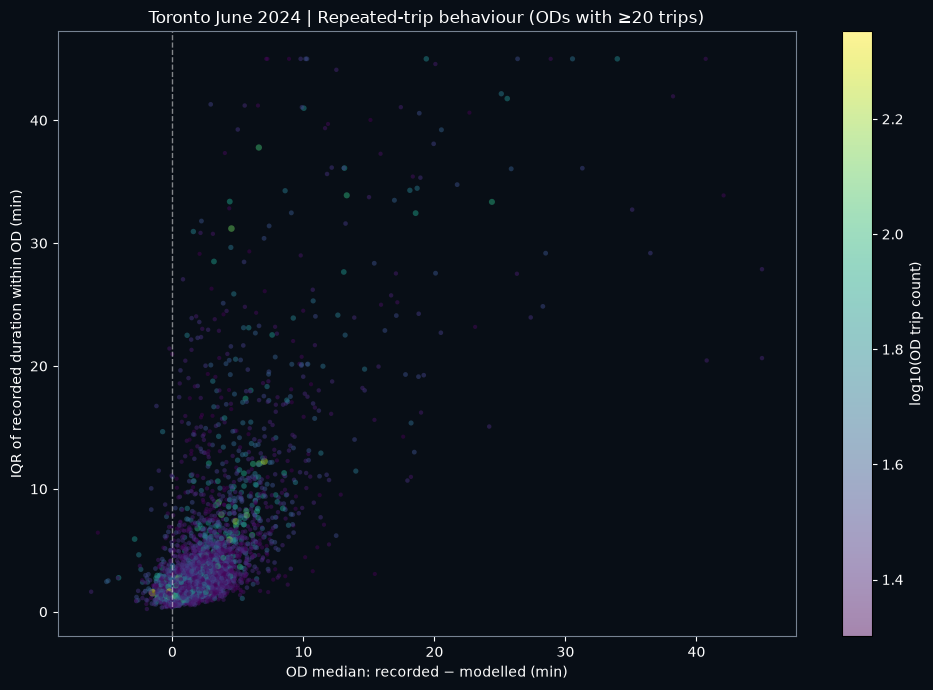

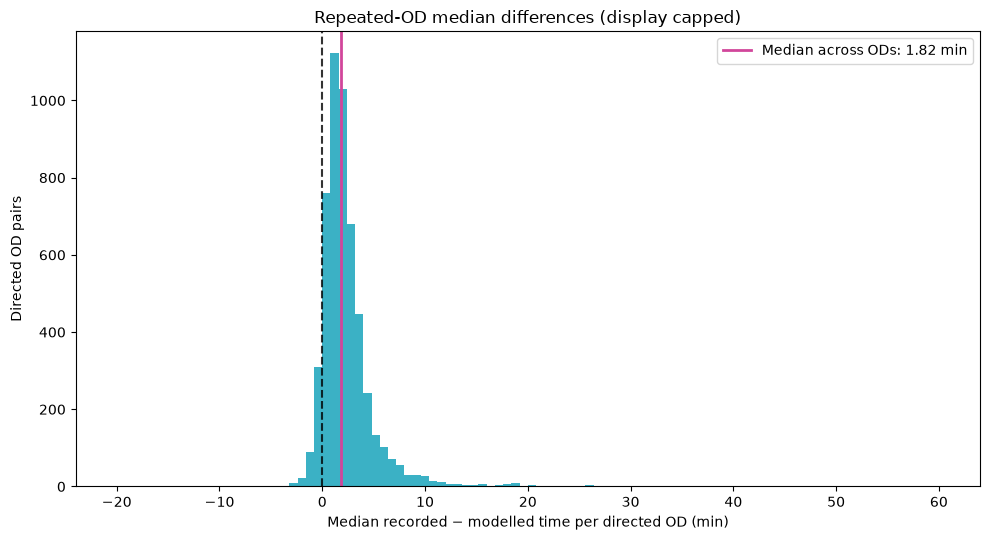

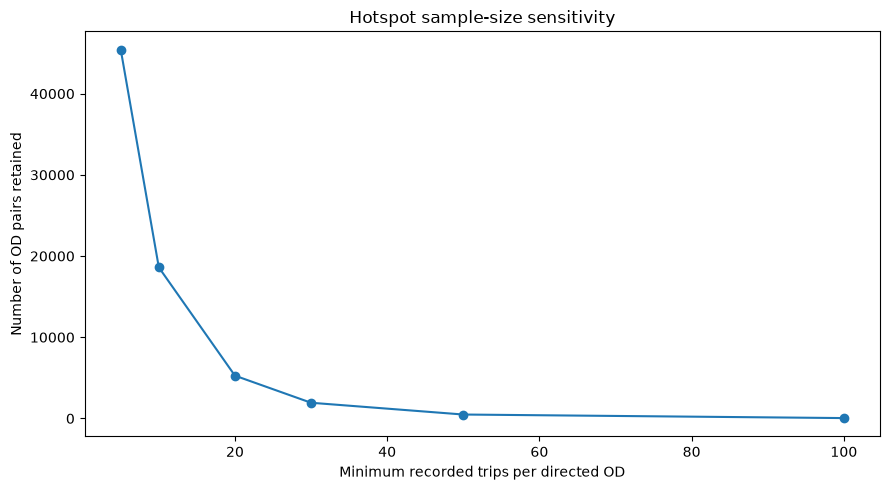

In [5]:
fig, ax = plt.subplots(figsize=(10,7), facecolor="#080e16")
ax.set_facecolor("#080e16")
z = eligible.copy()
sc = ax.scatter(
    z.median_delta_min.clip(-15, 45),
    z.iqr_observed_min.clip(0,45),
    s=np.clip(np.sqrt(z.n)*2, 4, 65),
    c=np.log10(z.n), cmap="viridis", alpha=.48, edgecolors="none"
)
ax.axvline(0, color="white", lw=1, ls="--", alpha=.5)
ax.set(xlabel="OD median: recorded − modelled (min)",
       ylabel="IQR of recorded duration within OD (min)",
       title=f"Toronto June 2024 | Repeated-trip behaviour (ODs with ≥{MIN_N} trips)")
ax.tick_params(colors="white")
for sp in ax.spines.values(): sp.set_color("#768292")
ax.xaxis.label.set_color("white"); ax.yaxis.label.set_color("white"); ax.title.set_color("white")
cb=fig.colorbar(sc,ax=ax,label="log10(OD trip count)")
cb.ax.yaxis.label.set_color("white"); cb.ax.tick_params(colors="white")
fig.tight_layout()
fig.savefig(OUT/"figure_A_OD_median_vs_variability.png",dpi=200,facecolor=fig.get_facecolor())
plt.show()

fig,ax=plt.subplots(figsize=(10,5.5))
ax.hist(eligible.median_delta_min.clip(-20,60),bins=np.linspace(-20,60,101),
        color="#18a4bb",alpha=.85)
ax.axvline(0,color="black",linestyle="--",alpha=.8)
ax.axvline(eligible.median_delta_min.median(),color="#d1469b",lw=2,
           label=f"Median across ODs: {eligible.median_delta_min.median():.2f} min")
ax.set(xlabel="Median recorded − modelled time per directed OD (min)",
       ylabel="Directed OD pairs",title="Repeated-OD median differences (display capped)")
ax.legend();fig.tight_layout()
fig.savefig(OUT/"figure_B_OD_median_distribution.png",dpi=200)
plt.show()

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(threshold_table.minimum_n,threshold_table.OD_pairs,marker="o")
ax.set(xlabel="Minimum recorded trips per directed OD",
       ylabel="Number of OD pairs retained",
       title="Hotspot sample-size sensitivity")
fig.tight_layout();fig.savefig(OUT/"figure_C_threshold_sensitivity.png",dpi=200)
plt.show()

## 5 — Separating bicycle types on the same OD
Report a separate **observed rental-duration comparison**, avoiding the inference that a common model speed is equally valid for e-bikes and conventional bikes. Only pairs with at least 5 trips of *each* type qualify here.

ODs with ≥5 rentals of each type: 2362
Median within-OD electric − conventional recorded duration: -0.933 minutes


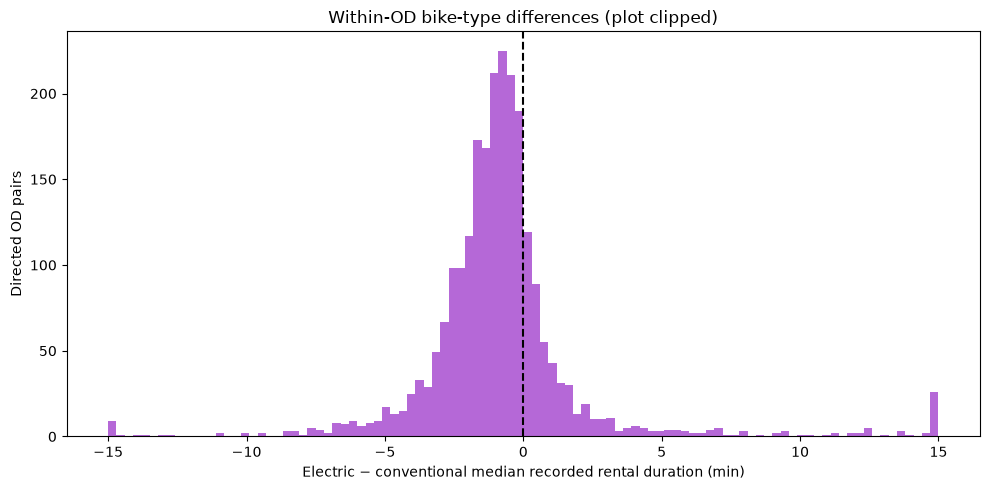

In [6]:
type_od = (
    df.groupby(KEYS+["bike_type"], observed=True)
      .agg(n=("observed_min","size"),
           median_observed_min=("observed_min","median"),
           iqr_observed_min=("observed_min", lambda x: x.quantile(.75)-x.quantile(.25)),
           median_delta_min=("delta_min","median"))
      .reset_index()
)
wide = type_od.pivot(index=KEYS,columns="bike_type",
                     values=["n","median_observed_min","iqr_observed_min","median_delta_min"])
wide.columns = [f"{m}_{b}" for m,b in wide.columns]
wide = wide.reset_index()
paired = wide.loc[
    (wide.get("n_Electric", pd.Series(index=wide.index,dtype=float)) >= 5) &
    (wide.get("n_Conventional", pd.Series(index=wide.index,dtype=float)) >= 5)
].copy()
paired["duration_gap_e_minus_c"] = (
    paired.median_observed_min_Electric - paired.median_observed_min_Conventional
)
paired.to_csv(OUT/"paired_type_OD_repeated_trip_summary.csv", index=False)
print("ODs with ≥5 rentals of each type:",len(paired))
print("Median within-OD electric − conventional recorded duration:",
      round(paired.duration_gap_e_minus_c.median(),3),"minutes")
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(paired.duration_gap_e_minus_c.clip(-15,15),bins=100,color="#a84ed1",alpha=.85)
ax.axvline(0,color="black",ls="--")
ax.set(xlabel="Electric − conventional median recorded rental duration (min)",
       ylabel="Directed OD pairs",title="Within-OD bike-type differences (plot clipped)")
fig.tight_layout()
fig.savefig(OUT/"figure_D_matched_type_duration.png",dpi=200)
plt.show()

## 6 — Spatial hotspot maps: routes and reference locations
Routes are **modelled GraphHopper paths**, not recorded cyclist trajectories. To avoid mapping highly unstable ODs, we plot only pairs with `n ≥ 20`. Maps show top-ranked **OD pairs** (not a street-segment exposure surface). Highlighting the whole modelled route does not mean riders actually followed it.

The SQLite geometry is loaded **only for the selected OD pairs**, reducing memory pressure.

Potential location errors need attention: the June 2024 station reference was constructed from mixed historical/current snapshots. Review suspicious station pairs manually before making scientific claims.

In [7]:
import geopandas as gpd
from shapely.geometry import shape

# A minimum of 20 trips, at least 500 metres, and a typical difference > 0
spatial_base = eligible.loc[
    eligible.distance_m >= 500
].copy()
TOP_K = 120

candidates = {
    "high_median_delta": spatial_base.nlargest(TOP_K,"median_delta_min"),
    "high_rental_variability": spatial_base.nlargest(TOP_K,"iqr_observed_min"),
}
selected = pd.concat(candidates.values(),ignore_index=True)[KEYS].drop_duplicates()
with sqlite3.connect(ROUTES) as con:
    con.execute("CREATE TEMP TABLE selected_od (start_id TEXT, end_id TEXT, PRIMARY KEY(start_id,end_id))")
    con.executemany(
        "INSERT OR IGNORE INTO selected_od VALUES (?,?)",
        list(selected[KEYS].itertuples(index=False, name=None))
    )
    routegeo = pd.read_sql_query(
        "SELECT r.start_id, r.end_id, r.geometry_json "
        "FROM routes r JOIN selected_od s "
        "ON r.start_id=s.start_id AND r.end_id=s.end_id "
        "WHERE r.geometry_json IS NOT NULL AND r.error IS NULL", con
    )
routegeo["start_id"] = norm_id(routegeo["start_id"])
routegeo["end_id"] = norm_id(routegeo["end_id"])
routegeo = routegeo.merge(selected,left_on=["start_id","end_id"],
                          right_on=KEYS,how="inner",validate="one_to_one")
routegeo["geometry"] = [shape(json.loads(v)) for v in routegeo.geometry_json]
groute = gpd.GeoDataFrame(routegeo.drop(columns=["geometry_json"]),
                          geometry="geometry",crs="EPSG:4326").to_crs("EPSG:26917")
print("Selected geographic routes:",len(groute)," / selected ODs:",len(selected))
print("Geometry types:",groute.geometry.geom_type.value_counts().to_dict())

Selected geographic routes: 175  / selected ODs: 175
Geometry types: {'LineString': 175}


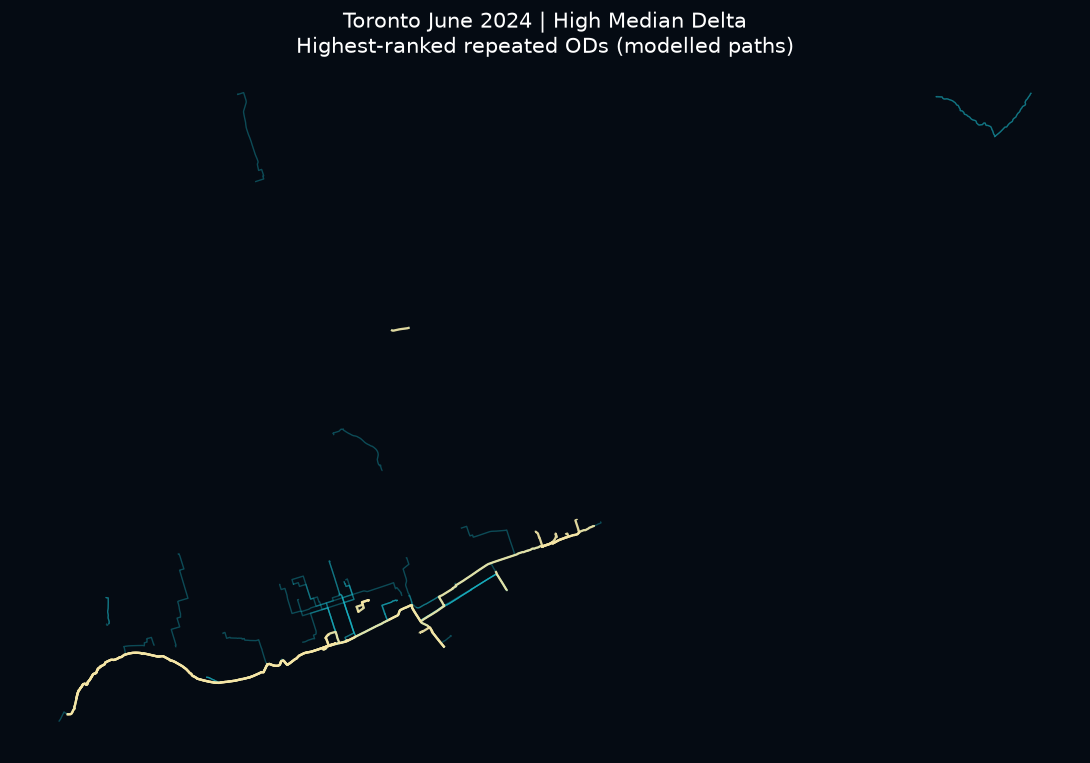

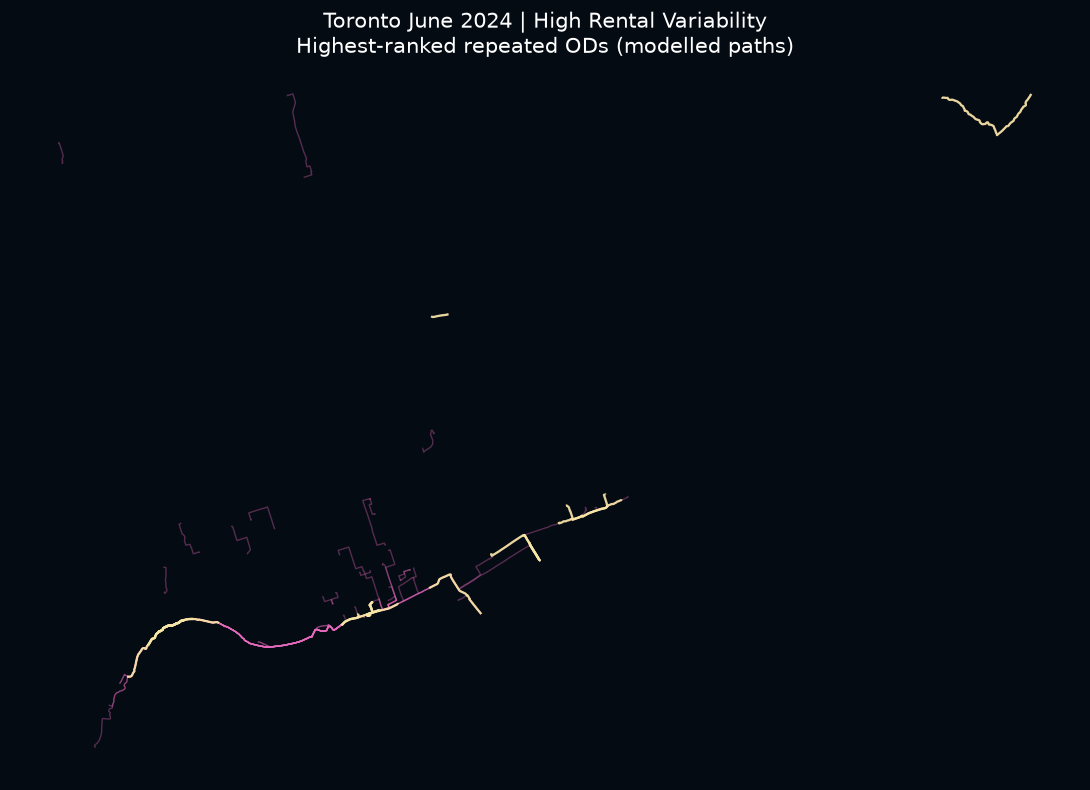

In [8]:
def map_hotspots(name, value_col, color, filename):
    ranking = candidates[name].copy().merge(
        groute[KEYS+["geometry"]], on=KEYS, how="inner",validate="one_to_one"
    )
    ranking = gpd.GeoDataFrame(ranking,geometry="geometry",crs="EPSG:26917")
    ranking = ranking.loc[ranking.geometry.notna() &
                          ranking.geometry.geom_type.eq("LineString")].copy()
    fig,ax=plt.subplots(figsize=(11,10),facecolor="#050b13")
    ax.set_facecolor("#050b13")
    ranking.plot(ax=ax,color=color,linewidth=1.0,alpha=.35)
    ranking.nlargest(25,value_col).plot(ax=ax,color="#f7e6a5",linewidth=1.65,alpha=.9)
    ax.set_axis_off()
    ax.set_title(f"Toronto June 2024 | {name.replace('_',' ').title()}\n"
                 "Highest-ranked repeated ODs (modelled paths)",color="white",fontsize=15)
    fig.tight_layout()
    fig.savefig(OUT/filename,dpi=200,facecolor=fig.get_facecolor(),bbox_inches="tight")
    plt.show()

map_hotspots("high_median_delta","median_delta_min","#1bc2d4","map_E_high_median_delta.png")
map_hotspots("high_rental_variability","iqr_observed_min","#e86bbf","map_F_high_duration_variability.png")

## 7 — Station-location confidence and review list
The OD and route databases do **not** certify the accuracy of June 2024 station coordinates. This cell enumerates available station reference columns, then exports high-priority OD review candidates.

If a provenance or station-movement field is present in your local station reference, inspect it manually and join it by the correct station identifier. No confidence score is invented here.

In [9]:
references = sorted(DATA.glob("*station*reference*.gpkg"))
if references:
    print("Station reference candidates:",[p.name for p in references])
    try:
        stations = gpd.read_file(references[0])
        print("Station reference columns:",stations.columns.tolist())
        print("Rows:",len(stations))
        display(stations.drop(columns="geometry",errors="ignore").head(3))
    except Exception as exc:
        print("Could not read station reference:",repr(exc))
else:
    print("No station reference GPKG found: review requires external station metadata.")
review = eligible.loc[
    eligible.flag_high_delta | eligible.flag_high_variability |
    eligible.flag_short_distance
].copy()
review["review_reason"] = np.select(
    [review.flag_short_distance,review.flag_high_delta,review.flag_high_variability],
    ["Short modelled distance","Large typical difference","High rental-duration IQR"],
    default="Other"
)
review.sort_values(["n","median_delta_min"],ascending=[False,False]).to_csv(
    OUT/"OD_quality_review_candidates.csv",index=False
)
print("Exported",len(review),"ODs for manual inspection")

Station reference candidates: ['bikeshare_station_reference_provisional.gpkg']
Station reference columns: ['station_id', 'name_2023', 'lat_2023', 'lon_2023', 'name_2026', 'lat_2026', 'lon_2026', 'lat', 'lon', 'coordinate_source', 'coordinate_difference_m', 'location_review_required', 'coordinate_verified_for_june_2024', 'geometry']
Rows: 1116


,station_id,name_2023,lat_2023,lon_2023,name_2026,lat_2026,lon_2026,lat,lon,coordinate_source,coordinate_difference_m,location_review_required,coordinate_verified_for_june_2024
0,7000,Fort York Blvd / Capreol Ct,43.639832,-79.395954,Fort York Blvd / Capreol Ct,43.639707,-79.396143,43.639832,-79.395954,2023_snapshot,20.624302,False,False
1,7001,Wellesley Station Green P,43.664964,-79.383550,Wellesley Station Green P,43.664964,-79.383550,43.664964,-79.383550,2023_snapshot,0.000000,False,False
2,7002,St. George St / Bloor St W,43.667333,-79.399429,St. George St / Bloor St W,43.667131,-79.399555,43.667333,-79.399429,2023_snapshot,24.621938,False,False


Exported 249 ODs for manual inspection


## 8 — Sensitivity: do apparent hotspot rankings persist?
Compare the top 50 OD hotspot lists at `n ≥ 10`, `n ≥ 20`, and `n ≥ 50`; changing membership shows that the apparent hotspot geography is partly a sample-size selection effect. This is not a formal uncertainty interval.

In [10]:
rankings = {}
for cutoff in [10,20,50]:
    z=od.loc[(od.n>=cutoff)&(od.distance_m>=500)]
    rankings[cutoff] = set(
        zip(z.nlargest(50,"median_delta_min").Start_Station_Id,
            z.nlargest(50,"median_delta_min").End_Station_Id)
    )
for a,b in [(10,20),(20,50),(10,50)]:
    print(f"Top-50 overlap n≥{a} versus n≥{b}: "
          f"{len(rankings[a]&rankings[b])} of 50")

Top-50 overlap n≥10 versus n≥20: 12 of 50
Top-50 overlap n≥20 versus n≥50: 9 of 50
Top-50 overlap n≥10 versus n≥50: 3 of 50


## 9 — Interpretation and next steps
**What these figures can support:** repeated OD-trip typical rental times, their variability, and model-relative differences, with explicit sample-size thresholds.

**What they cannot establish:** travelled trajectories, route deviations, inhaled pollution dose, or unnecessary travel time.

**Priorities after execution:**
1. Examine the quality-review CSV and station location provenance, particularly high-difference short-distance pairs.
2. Test threshold and outlier sensitivity of the hotspot list; consider uncertainty estimates using resampling *within ODs*.
3. For bicycle-type comparisons, retain the within-OD observed-duration metric and treat model speeds as sensitivity scenarios.
4. Only after these checks, integrate historical air quality and environmental exposure, preserving distinctions between ambient concentration–time and inhaled dose.